## Part 1
## 4. Aplicação de Métodos – Classificação

## Logistic Regression vs Linear Discriminant Analysis (LDA)

**Objetivo:** O objetivo deste estudo é prever `target_class` (N, HY, DI) ecomparar dois modelos de classificação: a regressão logística e a análise discriminante linear (LDA).

Ambos os modelos serão avaliados utilizando cinco abordagens de reamostragem:

1. Holdout
2. Validação cruzada em 5 dobras
3. Validação cruzada em 10 dobras
4. Validação cruzada «Leave-One-Out» (LOOCV)
5. Bootstrap

A análise irá comparar o desempenho preditivo e a variabilidade das métricas de avaliação entre os diferentes métodos de reamostragem.

Uma vez que a variável-alvo contém três classes de diagnóstico e que a distribuição das classes é desequilibrada, o Macro F1-score e a Precisão Equilibrada serão considerados a par da Precisão.

O objetivo final é identificar qual o modelo que oferece o melhor equilíbrio entre desempenho preditivo e estabilidade.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    LeaveOneOut,
    cross_val_predict,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

## 1. Carregamento do conjunto de dados

O conjunto de dados utilizado neste estudo é o que foi anteriormente analisado durante a análise exploratória dos dados (2 000 observações e 35 variáveis). 

A variável-alvo é `target_class`. A variável contínua `target_regression` não é utilizada como preditor, uma vez que se trata de outra
variável-alvo.

O conjunto de dados original é preservado. Quaisquer operações de pré-processamento serão realizadas num dataframe de modelação separado.

In [2]:
DATA_PATH = Path("dataset_grupo_08.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Não encontrei dataset_grupo_08.csv. "
        "Coloca o CSV na mesma pasta do notebook ou ajusta DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())



Dataset shape: (2000, 35)

Columns:
['age_level', 'gender', 'bmi_level', 'smoking', 'age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'employment_status', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression', 'target_class']


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Middle,Male,Obese,Never,44,0.482758,35.70,5.398540,250.000000,5.300000,...,69.000000,122.000000,Primary,Employed,116.000000,9.42,1.015947,160.000000,177.0,HY
1,Mature,Male,Obese,Former,49,0.540230,34.97,6.500000,224.684501,7.060728,...,63.592940,129.354661,Secondary,Unemployed,134.331495,9.42,1.245353,111.000000,80.0,N
2,Young,Male,Underweight,Never,4,0.022989,17.64,6.000000,228.130653,7.080402,...,65.713568,131.542714,Tertiary,Employed,133.010050,9.42,1.156861,130.259429,126.0,N
3,Middle,Male,Underweight,Current,40,0.436781,17.30,5.421429,299.000000,9.500000,...,52.000000,167.000000,Primary,Employed,124.000000,9.42,1.030313,176.000000,190.0,HY
4,Middle,Female,Normal,Current,27,0.287356,24.80,5.374373,277.000000,8.500000,...,31.000000,185.000000,Tertiary,Employed,96.000000,9.42,1.461792,143.000000,175.0,N


## 2. Análise inicial dos dados
Antes de treinar os modelos, analisamos a distribuição da variável-alvo, os tipos de dados, os valores em falta, as linhas duplicadas e os potenciais preditores redundantes.

Nesta fase, as colunas de preditores suspeitas não são automaticamente removidas. As suas características serão primeiro investigadas, para que qualquer decisão de as remover possa ser justificada com base em evidências.

As duas variáveis-alvo, `target_class` e `target_regression`, não devem ser incluídas entre os preditores.

Dataset dimensions: (2000, 35)
Duplicate rows: 0

Missing values per column:


age_level            0
ldl                  0
systolic_bp          0
diastolic_bp         0
alcohol_intake       0
salt_intake          0
heart_rate           0
hdl                  0
education_level      0
crp_level            0
employment_status    0
systolic_index       0
calcium_baseline     0
plasma_value         0
ldl_alternative      0
dtype: int64


Data types:


,Data type
age_level,object
gender,object
bmi_level,object
smoking,object
age,int64
age_normalized,float64
bmi,float64
HbA1c_level,float64
cholesterol,float64
sleep_hours,float64



Target class distribution:


,Count,Percentage
target_class,,
N,998,49.90
HY,669,33.45
DI,333,16.65


Text(0.5, 1.0, 'Percentage of observations per class')

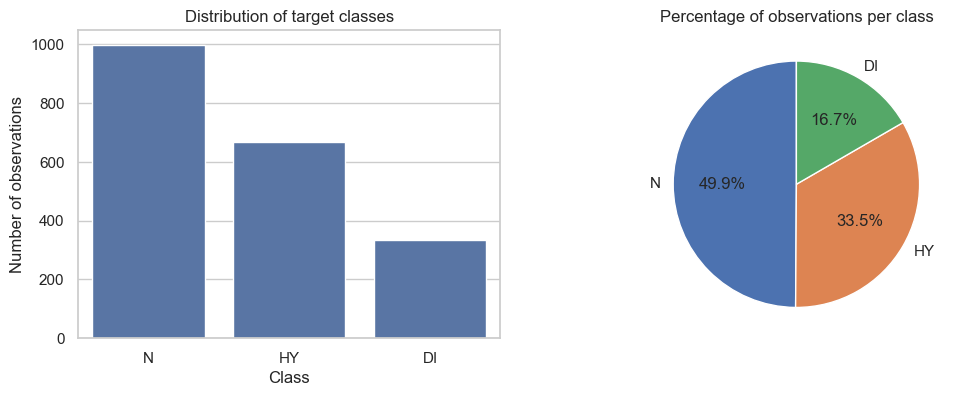

In [3]:
print("Dataset dimensions:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False).head(15))

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

if "target_class" not in df.columns:
    raise KeyError("A coluna 'target_class' não existe no dataset.")

print("\nTarget class distribution:")
display(
    df["target_class"]
      .value_counts()
      .rename("Count")
      .to_frame()
      .assign(
          Percentage=lambda x:
          (x["Count"] / len(df) * 100).round(2)
      )
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df,
    x="target_class",
    order=df["target_class"].value_counts().index,
    ax=axes[0]
)
axes[0].set_title("Distribution of target classes")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of observations")

class_counts = df["target_class"].value_counts()
axes[1].pie(
    class_counts.values,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Percentage of observations per class")

### 2.1 Variáveis preditoras potencialmente redundantes

A análise exploratória identificou algumas colunas que podem ser constantes, duplicadas ou derivadas de outras variáveis preditoras.

Entre os exemplos incluem-se `calcium_baseline`, `systolic_index` e `age_normalized`.

Estas variáveis não serão removidas automaticamente. Em primeiro lugar, iremos verificar a sua variância e as suas relações com outras variáveis.

Um preditor constante não contém informação que distinga as observações. Os preditores perfeitamente duplicados contêm informação redundante, embora a sua presença possa afetar os coeficientes do modelo e a estabilidade numérica.

A decisão final de remover uma coluna deve ser documentada e, quando útil, validada através da comparação do desempenho do modelo antes e
depois da remoção.

In [4]:
numeric_df = df.select_dtypes(include=np.number)

# Identificar colunas numéricas constantes
constant_columns = [
    col for col in numeric_df.columns
    if numeric_df[col].nunique(dropna=False) <= 1
]

print("Constant numeric columns:")
print(constant_columns)

# Identificar pares de colunas numéricas perfeitamente correlacionadas.
# A correlação não deteta todas as formas possíveis de duplicação,
# pelo que também verificamos igualdade exata.
numeric_predictors = numeric_df.drop(
    columns=["target_regression"],
    errors="ignore"
)

perfect_pairs = []

cols = numeric_predictors.columns.tolist()

for i, col1 in enumerate(cols):
    for col2 in cols[i + 1:]:
        s1 = numeric_predictors[col1]
        s2 = numeric_predictors[col2]

        if s1.equals(s2):
            perfect_pairs.append((col1, col2, "Exact equality"))
        elif s1.notna().all() and s2.notna().all():
            corr = s1.corr(s2)
            if np.isclose(abs(corr), 1.0, atol=1e-12):
                perfect_pairs.append(
                    (col1, col2, f"Correlation = {corr:.4f}")
                )

display(pd.DataFrame(
    perfect_pairs,
    columns=["Column 1", "Column 2", "Relationship"]
))

Constant numeric columns:
['calcium_baseline']


,Column 1,Column 2,Relationship
0,age,age_normalized,Correlation = 1.0000
1,systolic_bp,systolic_index,Exact equality


## 3. Preparação dos dados

A variável-alvo é `target_class`. A coluna `target_regression` é excluída dos preditores, uma vez que representa uma variável-alvo distinta.

Os preditores categóricos devem ser convertidos em variáveis numéricas. Será aplicada a codificação «one-hot» às colunas categóricas que
ainda não tenham sido codificadas.

Nesta fase, nenhum preditor potencialmente redundante é removido automaticamente. Os preditores constantes e redundantes são analisados
separadamente acima.

Para uma comparação justa, ambos os modelos utilizarão as mesmas observações, preditores, divisões e métricas de avaliação.

In [25]:
target = "target_class"

# Copiar os dados para preservar o dataframe original
model_df = df.copy()

# Identificar as colunas-alvo
target_columns = ["target_class", "target_regression"]

# 1. Ordinal encoding
ordinal_mappings = {
    "bmi_level": {
        "Underweight": 1,
        "Normal": 2,
        "Overweight": 3,
        "Obese": 4
    },
    "physical_activity": {
        "Low": 1,
        "Moderate": 2,
        "High": 3
    },
    "stress_level": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    },
    "sugar_consumption": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    }
}

for column, mapping in ordinal_mappings.items():
    model_df[column] = model_df[column].map(mapping)


# 2. Binary encoding
binary_mappings = {
    "gender": {
        "Male": 0,
        "Female": 1
    },
    "family_history": {
        "No": 0,
        "Yes": 1
    },
    "low_hdl_cholesterol": {
        "No": 0,
        "Yes": 1
    },
    "high_ldl_cholesterol": {
        "No": 0,
        "Yes": 1
    }
}

for column, mapping in binary_mappings.items():
    model_df[column] = model_df[column].map(mapping)


# 3. One-hot encoding
one_hot_categories = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "smoking": ["Never", "Former", "Current"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
    "employment_status": ["Unemployed", "Employed", "Retired"]
}

for column, categories in one_hot_categories.items():
    model_df[column] = pd.Categorical(
        model_df[column],
        categories=categories
    )

model_df = pd.get_dummies(
    model_df,
    columns=list(one_hot_categories.keys()),
    dtype=int
)


# 4. Separar a variável-alvo dos preditores
y = model_df[target].copy()

X_classification = model_df.drop(
    columns=target_columns,
    errors="ignore"
).copy()


# 5. Garantir que todos os preditores são numéricos
X_classification = X_classification.apply(pd.to_numeric, errors="raise")


# 6. Verificar valores em falta
if X_classification.isna().any().any():
    missing = X_classification.isna().sum()
    missing = missing[missing > 0]

    raise ValueError(
        "Existem valores em falta nos preditores:\n"
        f"{missing}"
    )

if y.isna().any():
    raise ValueError(
        "Existem valores em falta na variável-alvo."
    )


# 7. Verificar o resultado
print("X shape:", X_classification.shape)
print("y shape:", y.shape)

print("\nTarget classes:")
print(sorted(y.unique().tolist()))

print("\nTipos de dados dos preditores:")
display(X_classification.dtypes.to_frame("Data type"))

print("\nPrimeiras linhas de X:")
display(X_classification.head())

print("\nDistribuição das classes:")
display(y.value_counts().sort_index())

print("\nValores nulos em X:", X_classification.isna().sum().sum())
print("Valores nulos em y:", y.isna().sum())


X shape: (2000, 42)
y shape: (2000,)

Target classes:
['DI', 'HY', 'N']

Tipos de dados dos preditores:


,Data type
gender,int64
bmi_level,int64
age,int64
age_normalized,float64
bmi,float64
HbA1c_level,float64
cholesterol,float64
sleep_hours,float64
triglycerides,float64
physical_activity,int64



Primeiras linhas de X:


,gender,bmi_level,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,...,age_level_Senior,smoking_Never,smoking_Former,smoking_Current,education_level_Primary,education_level_Secondary,education_level_Tertiary,employment_status_Unemployed,employment_status_Employed,employment_status_Retired
0,0,4,44,0.482758,35.70,5.398540,250.000000,5.300000,235.000000,3,...,0,1,0,0,1,0,0,0,1,0
1,0,4,49,0.540230,34.97,6.500000,224.684501,7.060728,149.460563,2,...,0,0,1,0,0,1,0,1,0,0
2,0,1,4,0.022989,17.64,6.000000,228.130653,7.080402,156.115578,2,...,0,1,0,0,0,0,1,0,1,0
3,0,1,40,0.436781,17.30,5.421429,299.000000,9.500000,150.000000,1,...,0,0,0,1,1,0,0,0,1,0
4,1,2,27,0.287356,24.80,5.374373,277.000000,8.500000,187.000000,3,...,0,0,0,1,0,0,1,0,1,0



Distribuição das classes:


target_class
DI    333
HY    669
N     998
Name: count, dtype: int64


Valores nulos em X: 0
Valores nulos em y: 0


## 4. Modelos e métricas de avaliação

São considerados dois modelos de classificação:

- **Regressão logística**
- **Análise discriminante linear (LDA)**

O `StandardScaler` é incluído em cada pipeline para normalizar os valores dos preditores. Isto é particularmente importante para a regressão logística, onde a regularização pode ser afetada pela escala dos preditores.

Para a LDA, utiliza-se o solucionador `lsqr` com redução automática para melhorar a estimativa da matriz de covariância quando as variáveis preditoras estão correlacionadas.

São apresentadas as seguintes métricas:

- Precisão
- Precisão equilibrada
- Precisão macro
- Recall macro
- F1-score macro

As médias macro atribuem igual importância a cada classe. Isto é útil quando as classes-alvo estão desequilibradas.

O F1-score macro será a principal métrica para a comparação de modelos.

In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "LDA": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        ))
    ])
}

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

metrics = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro",
    "recall_macro": "recall_macro",
    "precision_macro": "precision_macro"
}
metric_map = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced accuracy",
    "f1_macro": "F1 macro",
    "recall_macro": "Recall macro",
    "precision_macro": "Precision macro"
}
print("Modelos:", list(models))

Modelos: ['Logistic Regression', 'LDA']


## 5. Regressão logística — Holdout

O método Holdout divide o conjunto de dados em dois subconjuntos independentes: um conjunto de treino e um conjunto de teste.

Neste caso, 80% das observações são utilizadas para treino e 20% para teste. A estratificação preserva aproximadamente as mesmas proporções de classes em ambos os subconjuntos.

O modelo é ajustado apenas com base nos dados de treino. Todas as métricas de teste apresentadas são calculadas a partir de previsões sobre observações não utilizadas para ajustar o modelo.

,Accuracy,Balanced Accuracy,Precision macro,Recall macro,F1 macro
Logistic Regression — Holdout,0.73,0.7503,0.7534,0.7503,0.7502


              precision    recall  f1-score   support

          DI       0.87      0.89      0.88        66
          HY       0.68      0.58      0.63       134
           N       0.71      0.78      0.74       200

    accuracy                           0.73       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.73      0.73      0.73       400



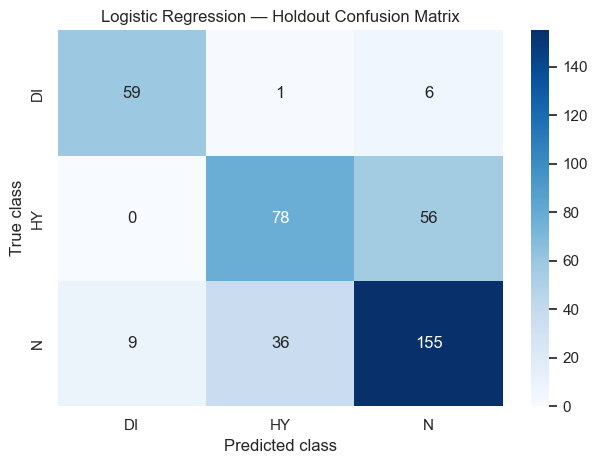

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X_classification,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

lr_holdout = clone(models["Logistic Regression"])

lr_holdout.fit(X_train, y_train)

lr_holdout_pred = lr_holdout.predict(X_test)

lr_holdout_metrics = calculate_metrics(y_test, lr_holdout_pred)

lr_holdout_results = pd.DataFrame(
    [lr_holdout_metrics],
    index=["Logistic Regression — Holdout"]
)

display(lr_holdout_results.round(4))

print(classification_report(
    y_test,
    lr_holdout_pred,
    zero_division=0
))

labels = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    lr_holdout_pred,
    labels=labels
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Logistic Regression — Holdout Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.show()

## 6. Regressão logística — Validação cruzada em 5 partes

Na validação cruzada em 5 partes, o conjunto de dados é dividido em cinco partes.

Em cada iteração, quatro partes são utilizadas para treino e a parte restante é utilizada para validação. Este processo é repetido até que cada parte tenha servido como conjunto de validação uma vez.

O StratifiedKFold preserva as proporções das classes em cada parte.

A pontuação média estima o desempenho preditivo médio, enquanto o desvio padrão descreve a variação entre as partes de validação.

In [27]:
def run_cross_validation(model, X, y, n_splits, seed=42):
    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=seed
    )

    result = cross_validate(
        clone(model),
        X,
        y,
        cv=cv,
        scoring=metrics,
        return_train_score=False,
        n_jobs=-1
    )

    fold_results = pd.DataFrame({
        metric: result[f"test_{metric}"]
        for metric in metrics
    })

    fold_results.index = [
        f"Fold {i}" for i in range(1, n_splits + 1)
    ]

    summary = pd.DataFrame({
        "Mean": fold_results.mean(),
        "Std": fold_results.std(ddof=1),
        "Minimum": fold_results.min(),
        "Maximum": fold_results.max()
    })

    return fold_results, summary


lr_cv5_folds, lr_cv5_summary = run_cross_validation(
    models["Logistic Regression"],
    X_classification,
    y,
    n_splits=5
)

display(lr_cv5_folds.round(4))
display(lr_cv5_summary.round(4))


,accuracy,balanced_accuracy,f1_macro,recall_macro,precision_macro
Fold 1,0.6850,0.6943,0.7078,0.6943,0.7253
Fold 2,0.6750,0.7030,0.7013,0.7030,0.7032
Fold 3,0.7175,0.7340,0.7341,0.7340,0.7447
Fold 4,0.7000,0.7272,0.7232,0.7272,0.7268
Fold 5,0.7575,0.7690,0.7776,0.7690,0.7922


,Mean,Std,Minimum,Maximum
accuracy,0.7070,0.0325,0.6750,0.7575
balanced_accuracy,0.7255,0.0294,0.6943,0.7690
f1_macro,0.7288,0.0301,0.7013,0.7776
recall_macro,0.7255,0.0294,0.6943,0.7690
precision_macro,0.7384,0.0335,0.7032,0.7922


## 7. Regressão logística — Validação cruzada em 10 partes

Na validação cruzada em 10 partes, o conjunto de dados é dividido em dez partes.

Cada modelo é treinado com aproximadamente 90% dos dados e avaliado com os restantes 10%. Cada observação é utilizada uma vez para validação.

Em comparação com a validação cruzada em 5 partes, cada subconjunto de treino é maior, mas há mais ajustes do modelo. A média e o desvio-padrão das pontuações das partes serão comparados com os resultados das 5 partes.

In [28]:
lr_cv10_folds, lr_cv10_summary= (
    run_cross_validation(
        models["Logistic Regression"],
        X_classification, y, n_splits=10
    )
)

display(lr_cv10_folds.round(4))
display(lr_cv10_summary.round(4))

,accuracy,balanced_accuracy,f1_macro,recall_macro,precision_macro
Fold 1,0.680,0.6833,0.6954,0.6833,0.7106
Fold 2,0.665,0.6837,0.6946,0.6837,0.7107
Fold 3,0.690,0.7088,0.7054,0.7088,0.7127
Fold 4,0.650,0.6873,0.6878,0.6873,0.6894
Fold 5,0.720,0.7321,0.7328,0.7321,0.7464
Fold 6,0.750,0.7671,0.7675,0.7671,0.7737
Fold 7,0.680,0.7140,0.7031,0.7140,0.7021
Fold 8,0.720,0.7423,0.7447,0.7423,0.7515
Fold 9,0.770,0.7904,0.7905,0.7904,0.7945
Fold 10,0.755,0.7580,0.7743,0.7580,0.7992


,Mean,Std,Minimum,Maximum
accuracy,0.7080,0.0411,0.6500,0.7700
balanced_accuracy,0.7267,0.0376,0.6833,0.7904
f1_macro,0.7296,0.0377,0.6878,0.7905
recall_macro,0.7267,0.0376,0.6833,0.7904
precision_macro,0.7391,0.0398,0.6894,0.7992


## 8. Regressão logística — Validação cruzada «Leave-One-Out»

A validação cruzada «Leave-One-Out» (LOOCV) é uma forma extrema de validação cruzada, na qual cada observação é utilizada uma vez como
amostra de validação.

Para um conjunto de dados que contenha n observações, o modelo é ajustado n vezes. Cada ajuste utiliza n-1 observações e prevê a única observação que foi deixada de fora.

As métricas finais são calculadas combinando todas as previsões fora de cada dobra. Isto produz uma previsão para cada observação.

Ao contrário da validação k-fold comum, cada dobra de teste LOOCV contém apenas uma observação. Por conseguinte, apresentar o desvio-padrão do Macro F1 por dobra não seria significativo. Em vez disso, apresentamos as métricas agregadas obtidas a partir de todas as previsões LOOCV.

In [29]:
def run_loocv(model, X, y):
    loo = LeaveOneOut()

    predictions = cross_val_predict(
        clone(model),
        X,
        y,
        cv=loo,
        n_jobs=-1,
        method="predict"
    )

    metrics = calculate_metrics(y, predictions)

    return metrics, predictions


lr_loocv_metrics, lr_loocv_pred = run_loocv(
    models["Logistic Regression"], X_classification, y
)

display(pd.DataFrame(
    [lr_loocv_metrics],
    index=["Logistic Regression — LOOCV"]
).round(4))

print(classification_report(
    y,
    lr_loocv_pred,
    zero_division=0
))

,Accuracy,Balanced Accuracy,Precision macro,Recall macro,F1 macro
Logistic Regression — LOOCV,0.7085,0.7275,0.7387,0.7275,0.7303


              precision    recall  f1-score   support

          DI       0.89      0.89      0.89       333
          HY       0.63      0.52      0.57       669
           N       0.69      0.78      0.73       998

    accuracy                           0.71      2000
   macro avg       0.74      0.73      0.73      2000
weighted avg       0.71      0.71      0.70      2000



## 9. Regressão logística — Bootstrap

O bootstrap faz amostragens repetidas de observações com reposição para criar conjuntos de dados de treino com o mesmo tamanho que o conjunto de dados original.

Em cada repetição, o modelo é treinado com base na amostra de bootstrap. As observações que não foram selecionadas nessa amostra são denominadas observações «out-of-bag» (OOB) e são utilizadas para avaliação.

As métricas OOB são registadas para cada repetição. A sua média e desvio padrão resumem o desempenho e a variabilidade ao longo das
repetições do bootstrap.

Uma repetição é ignorada se a sua amostra de treino não contiver todas as classes-alvo. Isto é necessário para uma avaliação multiclasse válida.

Valid Bootstrap repetitions: 200


,Mean,Std,Minimum,Maximum
Accuracy,0.7074,0.0140,0.6726,0.7408
Balanced Accuracy,0.7271,0.0134,0.6864,0.7612
Precision macro,0.7382,0.0139,0.6985,0.7769
Recall macro,0.7271,0.0134,0.6864,0.7612
F1 macro,0.7297,0.0129,0.6949,0.7613


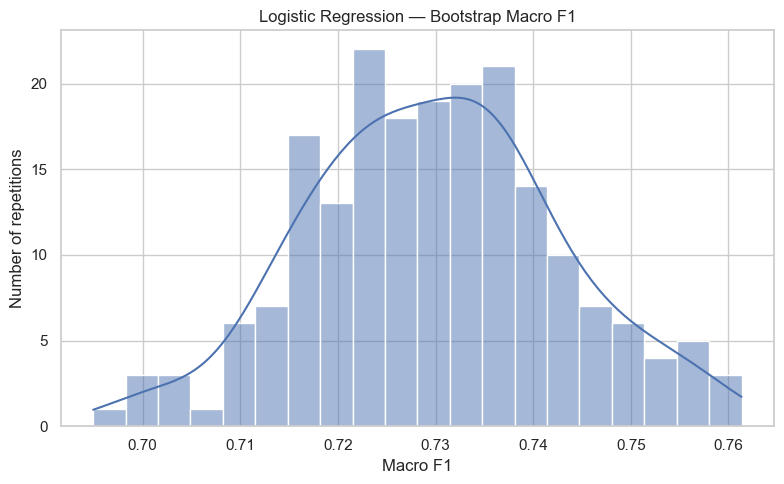

In [30]:
def run_bootstrap(
    model, X, y, n_bootstrap=200, seed=42
):
    rng = np.random.default_rng(seed)

    X_array = X.reset_index(drop=True)
    y_array = y.reset_index(drop=True)

    n = len(X_array)
    all_indices = np.arange(n)

    records = []

    for b in range(n_bootstrap):
        train_idx = rng.choice(
            all_indices,
            size=n,
            replace=True
        )

        # As observações OOB são as que não aparecem na amostra
        oob_mask = np.ones(n, dtype=bool)
        oob_mask[np.unique(train_idx)] = False
        oob_idx = all_indices[oob_mask]

        if len(oob_idx) == 0:
            continue

        X_boot = X_array.iloc[train_idx]
        y_boot = y_array.iloc[train_idx]

        # O modelo precisa de observar todas as classes
        if y_boot.nunique() != y.nunique():
            continue

        X_oob = X_array.iloc[oob_idx]
        y_oob = y_array.iloc[oob_idx]

        fitted_model = clone(model)
        fitted_model.fit(X_boot, y_boot)

        pred_oob = fitted_model.predict(X_oob)

        record = calculate_metrics(y_oob, pred_oob)
        record["Repetition"] = b + 1
        record["OOB observations"] = len(oob_idx)

        records.append(record)

    results = pd.DataFrame(records)

    if results.empty:
        raise RuntimeError(
            "Nenhuma repetição Bootstrap válida foi obtida."
        )

    results = results.set_index("Repetition")

    summary = pd.DataFrame({
        "Mean": results[list(calculate_metrics(y, y))].mean(),
        "Std": results[list(calculate_metrics(y, y))].std(ddof=1),
        "Minimum": results[list(calculate_metrics(y, y))].min(),
        "Maximum": results[list(calculate_metrics(y, y))].max()
    })

    return results, summary


lr_bootstrap_results, lr_bootstrap_summary = (
    run_bootstrap(
        models["Logistic Regression"],
        X_classification, y,
        n_bootstrap=200,
        seed=RANDOM_STATE
    )
)

print(
    "Valid Bootstrap repetitions:",
    len(lr_bootstrap_results)
)

display(lr_bootstrap_summary.round(4))

plt.figure(figsize=(8, 5))

sns.histplot(
    lr_bootstrap_results["F1 macro"],
    bins=20,
    kde=True
)

plt.title("Logistic Regression — Bootstrap Macro F1")
plt.xlabel("Macro F1")
plt.ylabel("Number of repetitions")
plt.tight_layout()
plt.show()

### Regressão logística — Conclusão provisória

Após executar as células anteriores, discuta:

- Qual foi o método que produziu o Macro F1-score mais elevado?
- Qual foi o método que produziu o Macro F1-score mais baixo?
- Em que medida os resultados variaram entre as dobras de CV?
- Quão variáveis foram os resultados do Bootstrap OOB?
- O custo computacional do LOOCV justificou-se pelos seus resultados?

As conclusões devem basear-se nos resultados reais, em vez de partir do pressuposto de que um método tem necessariamente um desempenho melhor do que outro.

## 10. LDA — Holdout

É utilizada a mesma divisão estratificada 80/20 utilizada para a regressão logística na LDA. Isto permite que os dois modelos sejam avaliados exatamente nas mesmas observações de teste.

A LDA estima as distribuições das classes e utiliza funções discriminantes para atribuir as observações às classes. Nesta experiência, o shrinkage está ativado para regularizar a estimativa da covariância.

,Accuracy,Balanced Accuracy,Precision macro,Recall macro,F1 macro
LDA — Holdout,0.725,0.7385,0.7474,0.7385,0.7421


              precision    recall  f1-score   support

          DI       0.86      0.85      0.85        66
          HY       0.66      0.60      0.63       134
           N       0.72      0.77      0.74       200

    accuracy                           0.72       400
   macro avg       0.75      0.74      0.74       400
weighted avg       0.72      0.72      0.72       400



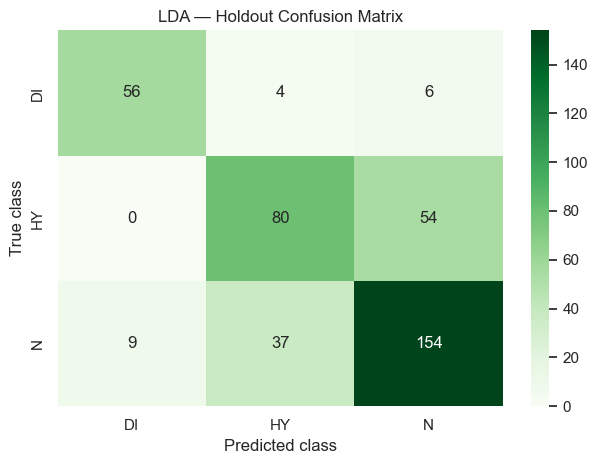

In [31]:
lda_holdout = clone(models["LDA"])


lda_holdout.fit(X_train, y_train)

lda_holdout_pred = lda_holdout.predict(X_test)
lda_holdout_metrics = calculate_metrics(y_test, lda_holdout_pred)

display(pd.DataFrame(
    [lda_holdout_metrics],
    index=["LDA — Holdout"]
).round(4))

print(classification_report(
    y_test,
    lda_holdout_pred,
    zero_division=0
))

cm = confusion_matrix(
    y_test,
    lda_holdout_pred,
    labels=labels
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("LDA — Holdout Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.show()

## 11. LDA — Validação cruzada

A LDA é avaliada utilizando validação cruzada estratificada em 5 e 10 partes. São utilizadas as mesmas partes, funções de pontuação e semente aleatória que nas experiências de regressão logística.

Para cada abordagem, indique as pontuações por parte, a média, o desvio padrão, o mínimo e o máximo.

In [32]:
lda_cv5_folds, lda_cv5_summary = (
    run_cross_validation(
        models["LDA"],
        X_classification, y, n_splits=5
    )
)

display(lda_cv5_folds.round(4))
display(lda_cv5_summary.round(4))

,accuracy,balanced_accuracy,f1_macro,recall_macro,precision_macro
Fold 1,0.6825,0.6875,0.7018,0.6875,0.7202
Fold 2,0.6700,0.6937,0.6966,0.6937,0.7021
Fold 3,0.7300,0.7422,0.7423,0.7422,0.7456
Fold 4,0.7025,0.7239,0.7290,0.7239,0.7388
Fold 5,0.7575,0.7641,0.7786,0.7641,0.7995


,Mean,Std,Minimum,Maximum
accuracy,0.7085,0.0356,0.6700,0.7575
balanced_accuracy,0.7223,0.0323,0.6875,0.7641
f1_macro,0.7297,0.0333,0.6966,0.7786
recall_macro,0.7223,0.0323,0.6875,0.7641
precision_macro,0.7412,0.0367,0.7021,0.7995


In [33]:
lda_cv10_folds, lda_cv10_summary= (
    run_cross_validation(
        models["LDA"],
        X_classification, y, n_splits=10
    )
)

display(lda_cv10_folds.round(4))
display(lda_cv10_summary.round(4))

,accuracy,balanced_accuracy,f1_macro,recall_macro,precision_macro
Fold 1,0.685,0.6932,0.7036,0.6932,0.7165
Fold 2,0.680,0.6868,0.7067,0.6868,0.7344
Fold 3,0.690,0.7020,0.7021,0.7020,0.7144
Fold 4,0.645,0.6788,0.6859,0.6788,0.6939
Fold 5,0.720,0.7286,0.7320,0.7286,0.7432
Fold 6,0.740,0.7551,0.7534,0.7551,0.7520
Fold 7,0.695,0.7187,0.7233,0.7187,0.7293
Fold 8,0.730,0.7506,0.7533,0.7506,0.7605
Fold 9,0.755,0.7658,0.7747,0.7658,0.7878
Fold 10,0.750,0.7563,0.7749,0.7563,0.8004


,Mean,Std,Minimum,Maximum
accuracy,0.7090,0.0356,0.6450,0.7550
balanced_accuracy,0.7236,0.0323,0.6788,0.7658
f1_macro,0.7310,0.0318,0.6859,0.7749
recall_macro,0.7236,0.0323,0.6788,0.7658
precision_macro,0.7432,0.0331,0.6939,0.8004


## 12. LDA — Validação cruzada «Leave-One-Out»

A LOOCV é realizada excluindo uma observação de cada vez. As previsões de todas as iterações são combinadas para calcular as
métricas de classificação agregadas.

As pontuações resultantes são diretamente comparáveis às obtidas a partir da regressão logística, uma vez que são utilizadas as mesmas observações e classes-alvo.

In [34]:
lda_loocv_metrics, lda_loocv_pred = run_loocv(
    models["LDA"], X_classification, y
)

display(pd.DataFrame(
    [lda_loocv_metrics],
    index=["LDA — LOOCV"]
).round(4))


print(classification_report(
    y,
    lda_loocv_pred,
    zero_division=0
))

,Accuracy,Balanced Accuracy,Precision macro,Recall macro,F1 macro
LDA — LOOCV,0.7055,0.7207,0.7386,0.7207,0.7281


              precision    recall  f1-score   support

          DI       0.90      0.85      0.88       333
          HY       0.62      0.55      0.58       669
           N       0.70      0.76      0.73       998

    accuracy                           0.71      2000
   macro avg       0.74      0.72      0.73      2000
weighted avg       0.70      0.71      0.70      2000



## 13. LDA — Bootstrap

O mesmo procedimento do Bootstrap é aplicado ao LDA, utilizando 200 repetições e avaliação «out-of-bag».

A utilização da mesma semente aleatória ajuda a tornar as amostras do bootstrap comparáveis entre modelos. No entanto, as repetições que não contêm todas as classes-alvo na amostra de treino são ignoradas.

Valid Bootstrap repetitions: 200


,Mean,Std,Minimum,Maximum
Accuracy,0.7035,0.0150,0.6598,0.7435
Balanced Accuracy,0.7178,0.0152,0.6676,0.7601
Precision macro,0.7388,0.0153,0.6946,0.7726
Recall macro,0.7178,0.0152,0.6676,0.7601
F1 macro,0.7257,0.0141,0.6819,0.7633


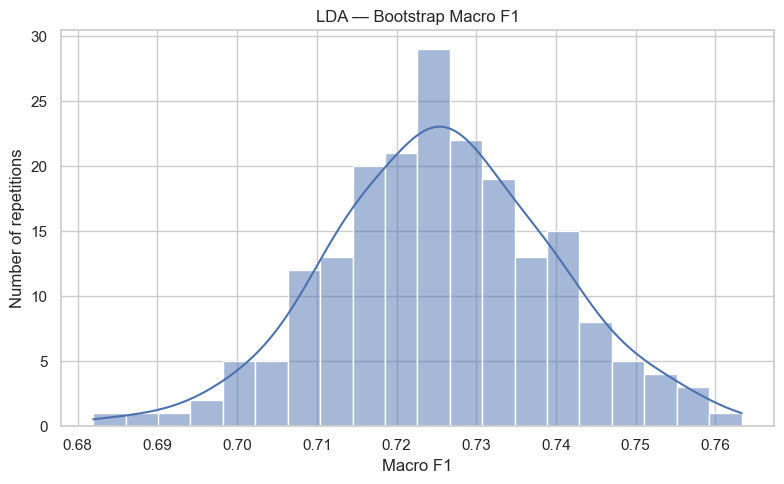

In [36]:
lda_bootstrap_results, lda_bootstrap_summary= (
    run_bootstrap(
        models["LDA"],
        X_classification, y,
        n_bootstrap=200,
        seed=RANDOM_STATE
    )
)

print(
    "Valid Bootstrap repetitions:",
    len(lda_bootstrap_results)
)

display(lda_bootstrap_summary.round(4))

plt.figure(figsize=(8, 5))

sns.histplot(
    lda_bootstrap_results["F1 macro"],
    bins=20,
    kde=True
)

plt.title("LDA — Bootstrap Macro F1")
plt.xlabel("Macro F1")
plt.ylabel("Number of repetitions")
plt.tight_layout()
plt.show()

### LDA — Conclusão provisória

Com base nos resultados, discuta:

- Qual foi o método de reamostragem que produziu o Macro F1-score mais elevado?
- Qual foi a variabilidade dos resultados entre as dobras de CV?
- Qual foi a variabilidade dos resultados do Bootstrap OOB?
- Qual foi o custo computacional do LOOCV?
- A redução de dimensão pareceu proporcionar uma solução estável?

A discussão deve basear-se nas métricas calculadas e nos gráficos apresentados.

## 14. Comparação global entre a regressão logística e o LDA

Esta secção reúne os resultados de ambos os modelos.

A principal métrica de comparação é o Macro F1-score, complementado pela Precisão Equilibrada, Macro Recall e Precisão.

No caso do Holdout e do LOOCV, as métricas correspondem a pontuações agregadas das respectivas previsões de teste. No caso do CV-5 e do CV-10, a média e o desvio-padrão apresentados são calculados em todas as dobras. No caso do Bootstrap, são calculados em todas as repetições OOB válidas.

Estas estimativas são informativas, mas não representam fontes idênticas de variação. As suas diferenças devem ser interpretadas
de acordo com a conceção de cada método de reamostragem.

In [21]:
comparison_rows = []

def add_comparison_row(model_name, method, metrics, std=None):
    # Normalizar os nomes das métricas para garantir consistência
    row = {
        "Model": model_name,
        "Method": method,
        "Accuracy": metrics.get("Accuracy", metrics.get("accuracy")),
        "Balanced Accuracy": metrics.get(
            "Balanced Accuracy", metrics.get("balanced_accuracy")
        ),
        "Macro Precision": metrics.get(
            "Macro Precision", metrics.get("macro_precision")
        ),
        "Macro Recall": metrics.get(
            "Macro Recall", metrics.get("macro_recall")
        ),
        "Macro F1": metrics.get("F1 macro", metrics.get("f1_macro")),
        "Macro F1 Std": std
    }

    comparison_rows.append(row)


# Logistic Regression
add_comparison_row(
    "Logistic Regression", "Holdout", lr_holdout_metrics
)

add_comparison_row(
    "Logistic Regression", "CV-5",
    lr_cv5_summary["Mean"].to_dict(),
    lr_cv5_summary.loc["f1_macro", "Std"]
)

add_comparison_row(
    "Logistic Regression", "CV-10",
    lr_cv10_summary["Mean"].to_dict(),
    lr_cv10_summary.loc["f1_macro", "Std"]
)

add_comparison_row(
    "Logistic Regression", "LOOCV", lr_loocv_metrics
)

add_comparison_row(
    "Logistic Regression", "Bootstrap",
    lr_bootstrap_summary["Mean"].to_dict(),
    lr_bootstrap_summary.loc["F1 macro", "Std"]
)


# LDA
add_comparison_row(
    "LDA", "Holdout", lda_holdout_metrics
)

add_comparison_row(
    "LDA", "CV-5",
    lda_cv5_summary["Mean"].to_dict(),
    lda_cv5_summary.loc["f1_macro", "Std"]
)

add_comparison_row(
    "LDA", "CV-10",
    lda_cv10_summary["Mean"].to_dict(),
    lda_cv10_summary.loc["f1_macro", "Std"]
)

add_comparison_row(
    "LDA", "LOOCV", lda_loocv_metrics
)

add_comparison_row(
    "LDA", "Bootstrap",
    lda_bootstrap_summary["Mean"].to_dict(),
    lda_bootstrap_summary.loc["F1 macro", "Std"]
)

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df
    .sort_values(["Method", "Model"])
    .round(4)
)

,Model,Method,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Macro F1 Std
9,LDA,Bootstrap,0.7035,0.7178,None,None,0.7257,0.0141
4,Logistic Regression,Bootstrap,0.7074,0.7271,None,None,0.7297,0.0129
7,LDA,CV-10,0.7090,0.7236,None,None,0.7310,0.0318
2,Logistic Regression,CV-10,0.7080,0.7267,None,None,0.7296,0.0377
6,LDA,CV-5,0.7085,0.7223,None,None,0.7297,0.0333
1,Logistic Regression,CV-5,0.7070,0.7255,None,None,0.7288,0.0301
5,LDA,Holdout,0.7250,0.7385,None,None,0.7421,NaN
0,Logistic Regression,Holdout,0.7300,0.7503,None,None,0.7502,NaN
8,LDA,LOOCV,0.7055,0.7207,None,None,0.7281,NaN
3,Logistic Regression,LOOCV,0.7085,0.7275,None,None,0.7303,NaN


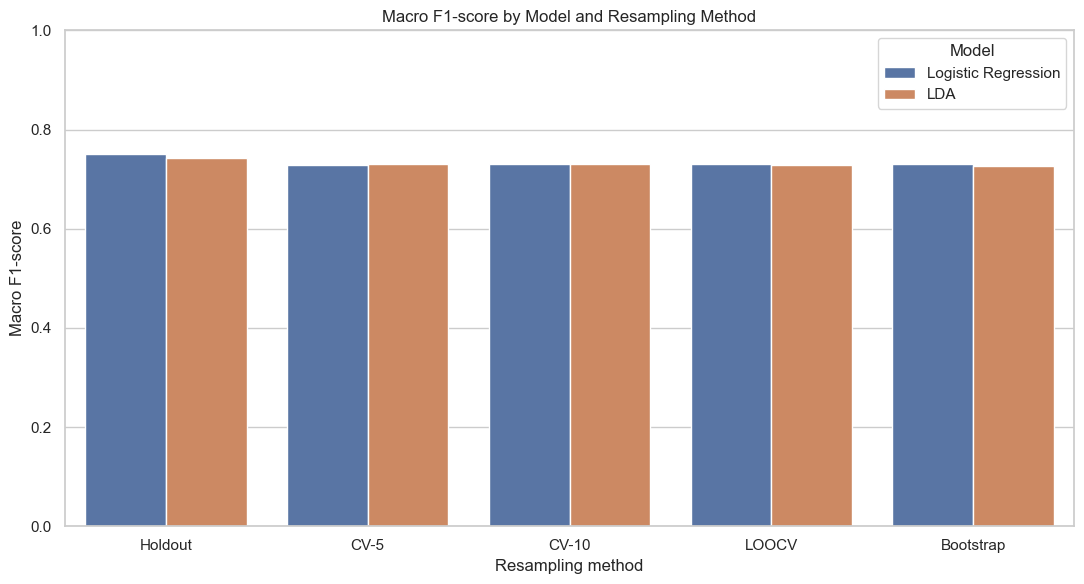

In [37]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_df,
    x="Method",
    y="Macro F1",
    hue="Model"
)

plt.title("Macro F1-score by Model and Resampling Method")
plt.ylabel("Macro F1-score")
plt.xlabel("Resampling method")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

### 14.1 Interpretação

Compare os dois modelos, método a método.

Um valor mais elevado do F1-score macro indica um melhor equilíbrio entre precisão e recall em todas as classes. A precisão equilibrada fornece informação adicional sobre a capacidade do modelo para identificar observações de cada classe.

Se um modelo apresentar um melhor desempenho na maioria dos métodos de reamostragem, isso constitui uma evidência mais sólida de uma vantagem consistente do que um único resultado de test de validação.

No entanto, pequenas diferenças entre as pontuações não devem ser automaticamente interpretadas como diferenças significativas no desempenho de generalização.

## 15. Análise da variância e da estabilidade

Esta secção avalia em que medida o Macro F1-score estimado varia sob diferentes procedimentos de avaliação.

Para o CV-5 e o CV-10, o desvio-padrão e a variância são calculados a partir dos resultados por fold. Para o Bootstrap, são calculados a partir dos resultados OOB em todas as repetições válidas.

O método «holdout» e o LOOCV produzem, cada um, uma pontuação agregada na presente experiência. Por conseguinte, não é possível estimar um desvio-padrão apenas a partir destes resultados isolados.

As estimativas de dispersão não são perfeitamente intercambiáveis, uma vez que os métodos utilizam modelos de avaliação diferentes. Em particular, a variação entre as dobras de CV não é a mesma que a variação entre as amostras de Bootstrap.

In [22]:
stability_rows = []

def add_stability(model_name, method, scores):
    scores = pd.Series(scores).dropna()

    stability_rows.append({
        "Model": model_name,
        "Method": method,
        "Number of estimates": len(scores),
        "Mean Macro F1": scores.mean(),
        "Std Macro F1": scores.std(ddof=1),
        "Variance Macro F1": scores.var(ddof=1),
        "Minimum Macro F1": scores.min(),
        "Maximum Macro F1": scores.max()
    })


# CV fold scores
add_stability(
    "Logistic Regression", "CV-5",
    lr_cv5_folds["f1_macro"]
)
add_stability(
    "Logistic Regression", "CV-10",
    lr_cv10_folds["f1_macro"]
)
add_stability(
    "LDA", "CV-5",
    lda_cv5_folds["f1_macro"]
)
add_stability(
    "LDA", "CV-10",
    lda_cv10_folds["f1_macro"]
)

# Bootstrap OOB scores
add_stability(
    "Logistic Regression", "Bootstrap",
    lr_bootstrap_results["F1 macro"]
)
add_stability(
    "LDA", "Bootstrap",
    lda_bootstrap_results["F1 macro"]
)

stability_df = pd.DataFrame(stability_rows)

display(
    stability_df
    .sort_values(["Method", "Model"])
    .round(5)
)

,Model,Method,Number of estimates,Mean Macro F1,Std Macro F1,Variance Macro F1,Minimum Macro F1,Maximum Macro F1
5,LDA,Bootstrap,200,0.72570,0.01406,0.00020,0.68195,0.76328
4,Logistic Regression,Bootstrap,200,0.72975,0.01288,0.00017,0.69495,0.76134
3,LDA,CV-10,10,0.73099,0.03181,0.00101,0.68592,0.77493
1,Logistic Regression,CV-10,10,0.72961,0.03773,0.00142,0.68779,0.79048
2,LDA,CV-5,5,0.72968,0.03325,0.00111,0.69664,0.77860
0,Logistic Regression,CV-5,5,0.72878,0.03015,0.00091,0.70127,0.77755


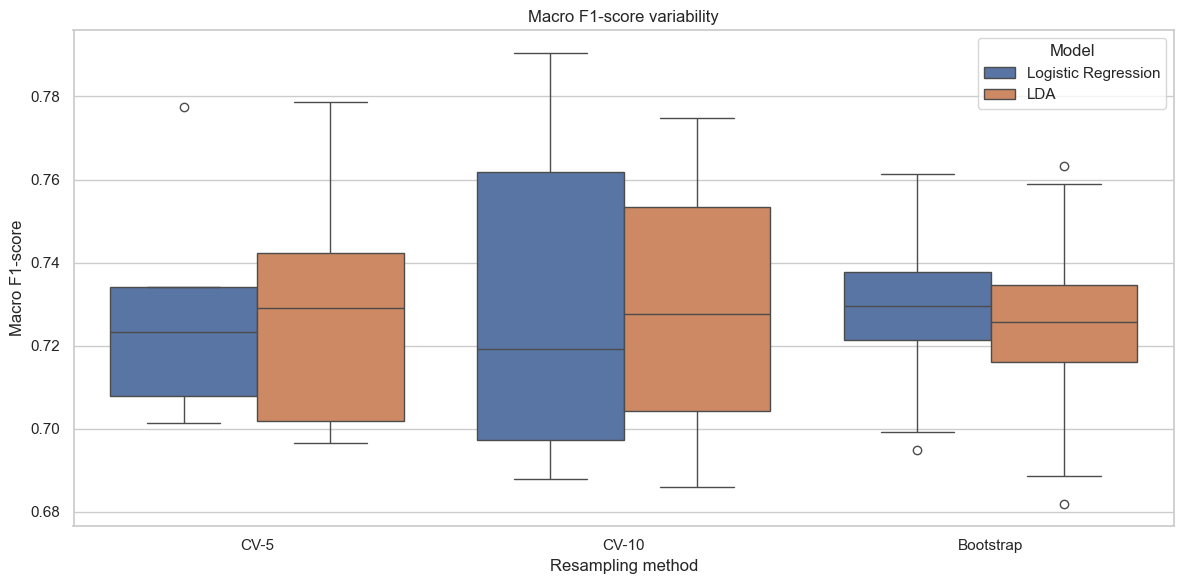

In [23]:
stability_plot_data = []

for model_name, results in [
    ("Logistic Regression", lr_cv5_folds),
    ("Logistic Regression", lr_cv10_folds),
    ("Logistic Regression", lr_bootstrap_results),
    ("LDA", lda_cv5_folds),
    ("LDA", lda_cv10_folds),
    ("LDA", lda_bootstrap_results)
]:
    if "f1_macro" in results.columns:
        scores = results["f1_macro"]
    else:
        scores = results["F1 macro"]

    method = (
        "CV-5" if len(scores) == 5 and "f1_macro" in results.columns
        else "CV-10" if len(scores) == 10 and "f1_macro" in results.columns
        else "Bootstrap"
    )

    for score in scores:
        stability_plot_data.append({
            "Model": model_name,
            "Method": method,
            "Macro F1": score
        })

stability_plot_df = pd.DataFrame(stability_plot_data)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=stability_plot_df,
    x="Method",
    y="Macro F1",
    hue="Model"
)

plt.title("Macro F1-score variability")
plt.ylabel("Macro F1-score")
plt.xlabel("Resampling method")
plt.tight_layout()
plt.show()

## 16. Discussão: impacto dos métodos de reamostragem na variância

### Holdout

O método Holdout é eficiente do ponto de vista computacional, mas o seu resultado depende da divisão específica entre dados de treino e de teste. Uma divisão diferente pode produzir uma estimativa diferente. Seria necessário repetir o método Holdout para quantificar
esta sensibilidade diretamente.

### Validação cruzada em 5 partes

Cada modelo é treinado com aproximadamente 80% dos dados em cada parte. O desvio-padrão entre as cinco pontuações indica em que medida
o desempenho varia entre estes subconjuntos de validação.

### Validação cruzada em 10 dobras

Cada modelo é treinado com aproximadamente 90% dos dados em cada dobra. Isto geralmente aumenta o tamanho do conjunto de treino por ajuste, mas cada dobra de validação é mais pequena. O desvio-padrão entre as dez dobras fornece informação sobre a variação entre as dobras, não uma medida completa da incerteza na estimativa da média.

### LOOCV

O LOOCV treina com n-1 observações de cada vez e utiliza cada observação uma única vez para o teste. Pode ser computacionalmente dispendioso. Uma vez que cada conjunto de teste contém apenas uma observação, o Macro F1 por conjunto não é adequado para uma análise direta da dispersão. Em vez disso, são apresentadas as métricas de previsão agregadas.

### Bootstrap

O Bootstrap cria repetidamente amostras de treino com reposição. As observações OOB fornecem um conjunto de avaliação para cada repetição.
O desvio-padrão entre as repetições mede a variação entre as estimativas OOB do Bootstrap.

### Interpretação geral

Um desvio-padrão mais baixo pode indicar estimativas mais consistentes no âmbito do procedimento de reamostragem correspondente. No entanto, os valores de dispersão obtidos a partir de métodos diferentes devem ser comparados com cautela, uma vez que resultam de diferentes desenhos de amostragem e validação.

O modelo preferido não deve ser selecionado com base apenas na variância. O desempenho preditivo, o equilíbrio entre classes, o custo computacional e a estabilidade devem ser todos tidos em conta.

## 17. Conclusões finais

Após a realização de todas as experiências, resuma os resultados respondendo às seguintes perguntas:

1. Qual foi o modelo que alcançou o maior Macro F1-score?
2. Qual foi o modelo que obteve a maior precisão equilibrada?
3. Os resultados foram consistentes entre o CV-5 e o CV-10?
4. Qual foi o modelo que apresentou menor variação nas repetições do Bootstrap?
5. Como se comparou o LOOCV com os outros métodos?
6. Qual foi o método que proporcionou o equilíbrio mais útil entre
   o custo computacional e a estimativa de desempenho?
7. Os dados justificaram a remoção de algum preditor constante ou redundante?
   predictors?

A seleção final do modelo deve basear-se nos resultados observados. Nenhum modelo deve ser declarado superior antes de as métricas terem sido calculadas e comparadas.

In [ ]:
"""comparison_df.to_csv(
    "classification_model_comparison.csv",
    index=False
)

stability_df.to_csv(
    "classification_stability_analysis.csv",
    index=False
)

print("Exported:")
print("- classification_model_comparison.csv")
print("- classification_stability_analysis.csv")"""